# Qwen3-4B configurable QLoRA training and evaluation

Fine-tune `Qwen/Qwen3-4B` for binary Sinhala offensive-language classification (`NOT=0`, `OFF=1`). Training and testing datasets are configured independently, allowing clean, transliteration, code-mix, or custom JSONL files in the same experiment.


## 1. Install dependencies

Run this cell once and restart the kernel before continuing.


In [1]:
%pip install -q -U "transformers>=4.45" "peft>=0.13" "accelerate>=1.0" "bitsandbytes>=0.46" "datasets>=3.0" pandas scikit-learn matplotlib seaborn


Note: you may need to restart the kernel to use updated packages.


## 2. Configuration


In [2]:
from pathlib import Path
import gc
import json
import os
import platform
import time

import numpy as np
import pandas as pd
import torch

SEED = 42
MODEL_ID = "Qwen/Qwen3-4B"
DATA_ROOT = None
OUTPUT_ROOT = Path("qwen4b/lora_results")

# Define every available dataset here. Paths are relative to DATA_ROOT.
# Custom JSONL files may be added with any unique name.
DATASETS = {
    "clean": {"train": Path("sold/train.jsonl"), "test": Path("sold/test.jsonl")},
    "transliteration_light": {"train": Path("outputs/train/transliteration_light.jsonl"), "test": Path("outputs/test/transliteration_light.jsonl")},
    "transliteration_heavy": {"train": Path("outputs/train/transliteration_heavy.jsonl"), "test": Path("outputs/test/transliteration_heavy.jsonl")},
    "codemix_light": {"train": Path("outputs/train/codemix_light.jsonl"), "test": Path("outputs/test/codemix_light.jsonl")},
    "codemix_heavy": {"train": Path("outputs/train/codemix_heavy.jsonl"), "test": Path("outputs/test/codemix_heavy.jsonl")},
}

# Select training runs and test sets independently.
TRAIN_DATASETS = ["transliteration_heavy"]
TEST_DATASETS = ["clean", "transliteration_light", "transliteration_heavy", "codemix_light", "codemix_heavy"]

TRAIN_SUBSET = None           # e.g. 200 for a smoke test
EPOCHS = 5.0
LEARNING_RATE = 1e-4
BATCH_SIZE = 2
GRADIENT_ACCUMULATION_STEPS = 16
MAX_LENGTH = 128
LORA_R = 16
VALIDATION_FRACTION = 0.10

LABEL_NAME = {0: "NOT", 1: "OFF"}
np.random.seed(SEED)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print("torch", torch.__version__, "| CUDA", torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError("QLoRA training requires a CUDA GPU.")
for i in range(torch.cuda.device_count()):
    props = torch.cuda.get_device_properties(i)
    print(f"cuda:{i} {props.name}, {props.total_memory / 2**30:.1f} GiB")


torch 2.13.0+cu130 | CUDA False


RuntimeError: QLoRA training requires a CUDA GPU.

## 3. Authenticate and locate data

Accept the gated Qwen model access requirements first. Set `HF_TOKEN` as an environment/Kaggle secret or authenticate interactively; never paste a token into the notebook.


In [ ]:
from huggingface_hub import login

hf_token = os.environ.get("HF_TOKEN")
if hf_token:
    login(token=hf_token, add_to_git_credential=False)
    print("Authenticated from HF_TOKEN.")
else:
    print("Using cached Hugging Face credentials; call login() interactively if required.")

unknown = (set(TRAIN_DATASETS) | set(TEST_DATASETS)) - set(DATASETS)
if unknown:
    raise KeyError(f"Undefined dataset names: {sorted(unknown)}")
if not TRAIN_DATASETS or not TEST_DATASETS:
    raise ValueError("TRAIN_DATASETS and TEST_DATASETS must both be non-empty.")

required_paths = []
for name in TRAIN_DATASETS:
    required_paths.append(DATASETS[name]["train"])
for name in TEST_DATASETS:
    required_paths.append(DATASETS[name]["test"])

def is_data_root(path):
    path = Path(path)
    return all((path / rel).is_file() for rel in required_paths)

def find_data_root(explicit=None):
    if explicit is not None:
        explicit = Path(explicit)
        if not is_data_root(explicit):
            raise FileNotFoundError(f"Selected files were not found below DATA_ROOT: {explicit.resolve()}")
        return explicit
    cwd = Path.cwd().resolve()
    for parent in (cwd, *cwd.parents):
        for candidate in (parent / "data", parent):
            if is_data_root(candidate):
                return candidate
    kaggle = Path("/kaggle/input")
    if kaggle.exists():
        for candidate in kaggle.iterdir():
            if candidate.is_dir() and is_data_root(candidate):
                return candidate
    raise FileNotFoundError("Could not locate all selected files. Set DATA_ROOT explicitly.")

DATA_ROOT = find_data_root(DATA_ROOT)
FILES = {}
for name in TRAIN_DATASETS:
    FILES[f"{name}_train"] = DATA_ROOT / DATASETS[name]["train"]
for name in TEST_DATASETS:
    FILES[f"{name}_test"] = DATA_ROOT / DATASETS[name]["test"]
print("DATA_ROOT =", DATA_ROOT.resolve())
display(pd.DataFrame([{"key": key, "path": str(path)} for key, path in FILES.items()]))


/home/cse_g6/.gpu-env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Authenticated from HF_TOKEN.
DATA_ROOT = /home/cse_g6/project/Sinhala-Noisy-Hatespeech-Data/data


,key,path
0,transliteration_heavy_train,/home/cse_g6/project/Sinhala-Noisy-Hatespeech-...
1,clean_test,/home/cse_g6/project/Sinhala-Noisy-Hatespeech-...
2,transliteration_light_test,/home/cse_g6/project/Sinhala-Noisy-Hatespeech-...
3,transliteration_heavy_test,/home/cse_g6/project/Sinhala-Noisy-Hatespeech-...
4,codemix_light_test,/home/cse_g6/project/Sinhala-Noisy-Hatespeech-...
5,codemix_heavy_test,/home/cse_g6/project/Sinhala-Noisy-Hatespeech-...


## 4. Load and validate aligned datasets


In [ ]:
def read_jsonl(path):
    with Path(path).open(encoding="utf-8") as handle:
        return pd.DataFrame(json.loads(line) for line in handle if line.strip())

def canonicalize(df, condition, split):
    id_candidates = ("post_id", "source_id", "id", "sentence_id", "orig_id")
    text_candidates = ("text", "noisy_text", "transliterated", "transliteration", "romanized")
    id_col = next((c for c in id_candidates if c in df.columns), None)
    text_col = next((c for c in text_candidates if c in df.columns), None)
    if id_col is None or text_col is None or "label" not in df.columns:
        raise KeyError(f"{condition}_{split}: unsupported columns {df.columns.tolist()}")
    out = df[[id_col, text_col, "label"]].rename(columns={id_col: "id", text_col: "text"}).copy()
    out["id"] = out["id"].astype(str)
    out["text"] = out["text"].astype(str)
    if out["label"].dtype == object:
        normalized = out["label"].astype(str).str.strip()
        out["label"] = normalized.map({"0": 0, "1": 1, "NOT": 0, "OFF": 1, "not": 0, "off": 1, "not-offensive": 0, "offensive": 1})
    if out["label"].isna().any():
        raise ValueError(f"{condition}_{split}: unmapped labels")
    out["label"] = out["label"].astype(int)
    if out["id"].duplicated().any() or out["text"].str.strip().eq("").any():
        raise ValueError(f"{condition}_{split}: duplicate IDs or empty text")
    if not set(out["label"]).issubset({0, 1}):
        raise ValueError(f"{condition}_{split}: labels must be 0/1")
    out["condition"], out["split"] = condition, split
    return out

frames = {}
for key, path in FILES.items():
    condition, split = key.rsplit("_", 1)
    frames[key] = canonicalize(read_jsonl(path), condition, split)
    counts = frames[key]["label"].value_counts().sort_index().to_dict()
    print(f"{key:32s}: n={len(frames[key])}, labels={counts}")

# Verify alignment only where datasets share a split and the same ID set.
for split, names in (("train", TRAIN_DATASETS), ("test", TEST_DATASETS)):
    split_frames = {name: frames[f"{name}_{split}"].set_index("id") for name in names}
    for left_index, left_name in enumerate(names):
        for right_name in names[left_index + 1:]:
            left, right = split_frames[left_name], split_frames[right_name]
            if set(left.index) == set(right.index):
                right = right.loc[left.index]
                if not np.array_equal(left["label"].to_numpy(), right["label"].to_numpy()):
                    raise ValueError(f"Label mismatch between aligned {left_name} and {right_name} {split} data")


transliteration_heavy_train     : n=7500, labels={0: 4324, 1: 3176}
clean_test                      : n=2500, labels={0: 1485, 1: 1015}
transliteration_light_test      : n=2500, labels={0: 1485, 1: 1015}
transliteration_heavy_test      : n=2500, labels={0: 1485, 1: 1015}
codemix_light_test              : n=2500, labels={0: 1485, 1: 1015}
codemix_heavy_test              : n=2500, labels={0: 1485, 1: 1015}


## 5. Tokenizer, QLoRA model, and datasets


In [ ]:
from datasets import ClassLabel, Dataset
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from transformers import (
    AutoModelForSequenceClassification, AutoTokenizer, BitsAndBytesConfig,
    DataCollatorWithPadding, set_seed,
)

COMPUTE_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16

def build_tokenizer():
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, use_fast=True)
    tokenizer.padding_side = "right"
    if tokenizer.pad_token_id is None:
        tokenizer.pad_token = tokenizer.eos_token
    return tokenizer

def make_dataset(frame, tokenizer):
    dataset = Dataset.from_pandas(frame[["id", "text", "label"]], preserve_index=False)
    dataset = dataset.cast_column("label", ClassLabel(names=["NOT", "OFF"]))
    return dataset.map(
        lambda batch: tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH),
        batched=True,
        remove_columns=["text"],
    )

def build_model(tokenizer):
    quantization = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=COMPUTE_DTYPE,
    )
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_ID,
        num_labels=2,
        id2label=LABEL_NAME,
        label2id={"NOT": 0, "OFF": 1},
        pad_token_id=tokenizer.pad_token_id,
        quantization_config=quantization,
        device_map="auto",
        dtype=COMPUTE_DTYPE,
        low_cpu_mem_usage=True,
        attn_implementation="sdpa",
    )
    model.config.use_cache = False
    model = prepare_model_for_kbit_training(
        model,
        use_gradient_checkpointing=True,
        gradient_checkpointing_kwargs={"use_reentrant": False},
    )
    model.enable_input_require_grads()
    model = get_peft_model(model, LoraConfig(
        task_type="SEQ_CLS",
        r=LORA_R,
        lora_alpha=2 * LORA_R,
        lora_dropout=0.05,
        bias="none",
        target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
        modules_to_save=["score"],
    ))
    model.print_trainable_parameters()
    return model


## 6. Train and evaluate

Macro-F1 is the primary metric. Class-weighted loss compensates for SOLD imbalance. The validation split is drawn only from the selected training condition; test data is never used for checkpoint selection.


In [ ]:
import dataclasses
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    f1_score, precision_recall_fscore_support,
)
from transformers import Trainer, TrainingArguments

def metric_values(labels, predictions):
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predictions, labels=[0, 1], zero_division=0
    )
    return {
        "accuracy": accuracy_score(labels, predictions),
        "balanced_accuracy": balanced_accuracy_score(labels, predictions),
        "macro_f1": f1_score(labels, predictions, average="macro", zero_division=0),
        "not_precision": precision[0], "not_recall": recall[0], "not_f1": f1[0],
        "off_precision": precision[1], "off_recall": recall[1], "off_f1": f1[1],
    }

def compute_metrics(eval_prediction):
    logits, labels = eval_prediction
    return metric_values(labels, np.argmax(logits, axis=-1))

class WeightedTrainer(Trainer):
    def __init__(self, class_weights=None, **kwargs):
        super().__init__(**kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        weights = self.class_weights.to(outputs.logits.device, outputs.logits.dtype)
        loss = nn.CrossEntropyLoss(weight=weights)(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

def training_arguments(output_dir):
    kwargs = dict(
        output_dir=str(output_dir / "checkpoints"),
        seed=SEED,
        num_train_epochs=EPOCHS,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=BATCH_SIZE,
        gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
        eval_accumulation_steps=8,
        learning_rate=LEARNING_RATE,
        lr_scheduler_type="cosine",
        warmup_ratio=0.06,
        weight_decay=0.01,
        max_grad_norm=0.3,
        fp16=not torch.cuda.is_bf16_supported(),
        bf16=torch.cuda.is_bf16_supported(),
        optim="paged_adamw_8bit",
        gradient_checkpointing=True,
        gradient_checkpointing_kwargs={"use_reentrant": False},
        logging_steps=25,
        eval_strategy="epoch",
        save_strategy="epoch",
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        report_to="none",
        dataloader_num_workers=2,
        dataloader_pin_memory=False,
        group_by_length=True,
        label_names=["labels"],
    )
    valid = {field.name for field in dataclasses.fields(TrainingArguments)}
    return TrainingArguments(**{key: value for key, value in kwargs.items() if key in valid})

def run_condition(condition):
    set_seed(SEED)
    output_dir = OUTPUT_ROOT / f"train_{condition}_seed{SEED}"
    output_dir.mkdir(parents=True, exist_ok=True)

    train_frame = frames[f"{condition}_train"].copy()
    if TRAIN_SUBSET is not None:
        train_frame = train_frame.sample(
            n=min(TRAIN_SUBSET, len(train_frame)), random_state=SEED
        ).reset_index(drop=True)

    tokenizer = build_tokenizer()
    full_train = make_dataset(train_frame, tokenizer)
    split = full_train.train_test_split(
        test_size=VALIDATION_FRACTION, seed=SEED, stratify_by_column="label"
    )
    train_ds, validation_ds = split["train"], split["test"]
    counts = np.bincount(np.asarray(train_ds["label"]), minlength=2)
    class_weights = torch.tensor(
        counts.sum() / (2.0 * np.maximum(counts, 1)), dtype=torch.float32
    )
    print(f"{condition}: train={len(train_ds)}, validation={len(validation_ds)}, counts={counts.tolist()}")

    model = build_model(tokenizer)
    trainer = WeightedTrainer(
        model=model,
        args=training_arguments(output_dir),
        train_dataset=train_ds,
        eval_dataset=validation_ds,
        data_collator=DataCollatorWithPadding(tokenizer, pad_to_multiple_of=8),
        compute_metrics=compute_metrics,
        class_weights=class_weights,
    )
    train_result = trainer.train()
    trainer.model.save_pretrained(output_dir / "adapter")
    tokenizer.save_pretrained(output_dir / "adapter")

    result_rows, prediction_frames = [], []
    for test_condition in TEST_DATASETS:
        test_frame = frames[f"{test_condition}_test"].copy()
        test_ds = make_dataset(test_frame, tokenizer)
        output = trainer.predict(test_ds)
        predictions = np.argmax(output.predictions, axis=-1)
        metrics = metric_values(np.asarray(test_ds["label"]), predictions)
        result_rows.append({
            "train_condition": condition,
            "test_condition": test_condition,
            "n": len(test_ds),
            **metrics,
        })
        prediction_frames.append(pd.DataFrame({
            "id": test_frame["id"],
            "train_condition": condition,
            "test_condition": test_condition,
            "label": test_frame["label"],
            "prediction": predictions,
        }))
        print(f"\n=== train={condition}, test={test_condition} ===")
        print(classification_report(
            test_frame["label"], predictions,
            labels=[0, 1], target_names=["NOT", "OFF"], digits=4, zero_division=0,
        ))

    results = pd.DataFrame(result_rows)
    predictions = pd.concat(prediction_frames, ignore_index=True)
    results.to_csv(output_dir / "metrics.csv", index=False)
    predictions.to_json(
        output_dir / "predictions.jsonl", orient="records", lines=True, force_ascii=False
    )
    with (output_dir / "run_summary.json").open("w", encoding="utf-8") as handle:
        json.dump({
            "model_id": MODEL_ID,
            "train_condition": condition,
            "seed": SEED,
            "train_rows": len(train_ds),
            "validation_rows": len(validation_ds),
            "epochs": EPOCHS,
            "learning_rate": LEARNING_RATE,
            "lora_r": LORA_R,
            "max_length": MAX_LENGTH,
            "train_metrics": train_result.metrics,
            "test_metrics": result_rows,
        }, handle, indent=2, default=float)

    del trainer, model, tokenizer, train_ds, validation_ds
    gc.collect()
    torch.cuda.empty_cache()
    return results, predictions


## 7. Run configured experiments and save the robustness matrix

A full three-condition run can take many hours. Start with `TRAIN_SUBSET=200` for a smoke test before setting it back to `None`.


In [ ]:
all_results = []
all_predictions = []
started = time.time()

for condition in TRAIN_DATASETS:
    print("\n" + "=" * 72)
    print("TRAIN CONDITION:", condition)
    print("=" * 72)
    condition_results, condition_predictions = run_condition(condition)
    all_results.append(condition_results)
    all_predictions.append(condition_predictions)

results = pd.concat(all_results, ignore_index=True)
predictions = pd.concat(all_predictions, ignore_index=True)
results.to_csv(OUTPUT_ROOT / "all_metrics.csv", index=False)
predictions.to_json(
    OUTPUT_ROOT / "all_predictions.jsonl", orient="records", lines=True, force_ascii=False
)

matrix = results.pivot(index="train_condition", columns="test_condition", values="macro_f1")
matrix.to_csv(OUTPUT_ROOT / "macro_f1_matrix.csv")
display(results.round(4))
display(matrix.round(4))
print(f"Finished in {(time.time() - started) / 3600:.2f} hours")
print("Artifacts:", OUTPUT_ROOT.resolve())



TRAIN CONDITION: transliteration_heavy


Map: 100%|██████████| 7500/7500 [00:00<00:00, 29756.49 examples/s]


transliteration_heavy: train=6750, validation=750, counts=[3892, 2858]


Loading weights: 100%|██████████| 398/398 [00:03<00:00, 123.10it/s]
[transformers] Qwen3ForSequenceClassification LOAD REPORT from: Qwen/Qwen3-4B
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 33,035,264 || all params: 4,055,508,480 || trainable%: 0.8146


[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!


Epoch,Training Loss,Validation Loss,Accuracy,Balanced Accuracy,Macro F1,Not Precision,Not Recall,Not F1,Off Precision,Off Recall,Off F1
1,9.143682,0.475677,0.788000,0.776555,0.779768,0.794816,0.851852,0.822346,0.777003,0.701258,0.737190
2,5.706169,0.449682,0.792000,0.791230,0.788680,0.834951,0.796296,0.815166,0.739645,0.786164,0.762195
3,4.051774,0.492439,0.806667,0.795663,0.799160,0.809935,0.868056,0.837989,0.801394,0.723270,0.760331
4,0.993527,1.427299,0.818667,0.807739,0.811524,0.818966,0.879630,0.848214,0.818182,0.735849,0.774834
5,0.024342,1.680038,0.824000,0.815688,0.818197,0.831858,0.870370,0.850679,0.812081,0.761006,0.785714


Map: 100%|██████████| 2500/2500 [00:00<00:00, 38242.96 examples/s]


## 8. Plot results


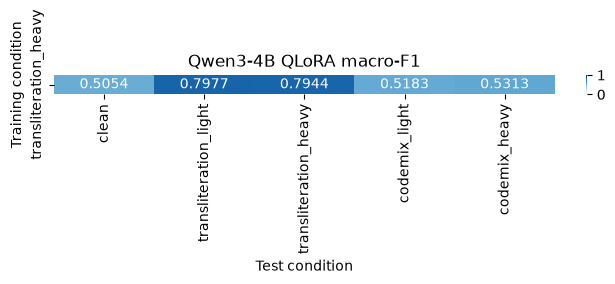

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, max(2.5, 0.8 * len(matrix))))
sns.heatmap(matrix.reindex(columns=TEST_DATASETS), annot=True, fmt=".4f", cmap="Blues", vmin=0, vmax=1)
plt.title("Qwen3-4B QLoRA macro-F1")
plt.xlabel("Test condition")
plt.ylabel("Training condition")
plt.tight_layout()
plt.savefig(OUTPUT_ROOT / "macro_f1_matrix.png", dpi=180, bbox_inches="tight")
plt.show()


## Reporting checklist

Report the base-model revision/date, LoRA targets/rank, quantization, training condition and size, validation policy, seed, epochs, learning rate, effective batch size, truncation length, and clean/light/heavy metrics. Keep smoke-test results separate from full-data results. Do not select hyperparameters using the test sets.
